In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
df= pd.read_csv("online_coupon_sales.csv")

In [3]:
df.head()


,purchase_id,customer_id,product_name,coupon_type,original_price,final_price,purchase_date,sales_amount
0,1,101,Shampoo,Discount,120,100,2022-01-01,1
1,2,102,Soap,Cashback,30,25,2022-04-01,2
2,3,103,Toothpaste,Discount,80,65,2022-06-30,1
3,4,104,Lotion,Free Item,250,250,2022-09-28,1
4,5,105,Shampoo,Discount,120,90,2022-12-27,2


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   purchase_id     10 non-null     int64 
 1   customer_id     10 non-null     int64 
 2   product_name    10 non-null     object
 3   coupon_type     10 non-null     object
 4   original_price  10 non-null     int64 
 5   final_price     10 non-null     int64 
 6   purchase_date   10 non-null     object
 7   sales_amount    10 non-null     int64 
dtypes: int64(5), object(3)
memory usage: 772.0+ bytes


In [5]:
df.describe(include='all')

,purchase_id,customer_id,product_name,coupon_type,original_price,final_price,purchase_date,sales_amount
count,10.00000,10.000000,10,10,10.000000,10.000000,10,10.000000
unique,NaN,NaN,5,3,NaN,NaN,10,NaN
top,NaN,NaN,Shampoo,Discount,NaN,NaN,2022-01-01,NaN
freq,NaN,NaN,3,4,NaN,NaN,1,NaN
mean,5.50000,104.600000,NaN,NaN,112.500000,95.500000,NaN,1.600000
std,3.02765,2.875181,NaN,NaN,80.458754,74.589618,NaN,0.699206
min,1.00000,101.000000,NaN,NaN,30.000000,25.000000,NaN,1.000000
25%,3.25000,102.250000,NaN,NaN,53.750000,45.000000,NaN,1.000000
50%,5.50000,104.500000,NaN,NaN,100.000000,77.500000,NaN,1.500000
75%,7.75000,106.750000,NaN,NaN,120.000000,100.000000,NaN,2.000000


In [6]:
#  Check for Null Values (with %)

null_counts = df.isnull().sum()
null_percentage = (null_counts / len(df)) *100
null_df = pd.DataFrame({ 'Null Count': null_counts, 'Null Percentage': null_percentage})
null_df.sort_values(by='Null Percentage', ascending=False)

,Null Count,Null Percentage
purchase_id,0,0.0
customer_id,0,0.0
product_name,0,0.0
coupon_type,0,0.0
original_price,0,0.0
final_price,0,0.0
purchase_date,0,0.0
sales_amount,0,0.0


In [7]:
# Drop Columns with High Null % (e.g., >50%)

high_null_cols = null_df[ null_df['Null Percentage']> 50].index
df.drop(columns=high_null_cols, inplace=True)

In [8]:
#  Drop Unwanted Columns

unwanted_cols = ['Unwanted: 0', 'costomer_id']
df.drop(columns=[ col for col in unwanted_cols if col in df.columns],inplace=True)

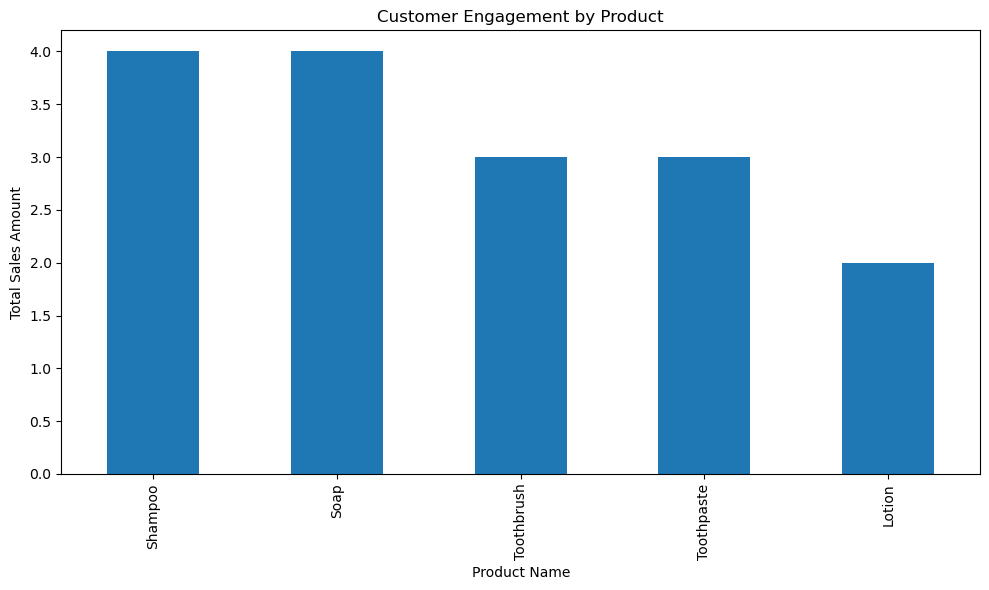

In [9]:
#  Sort by Sales Amount if available

if 'sale_amount' in df.columns:
    df_sort_values(by='sale_amount',ascending=False)

# Create sales_amount if it's missing, assuming it's final_price × sales quantity
if 'sales_amount' not in df.columns:
    df['sales_amount'] = df['final_price'] * df['sales_amount'].fillna(1)

# Ensure 'sales_amount' column exists
if 'sales_amount' not in df.columns:
    df['sales_amount'] = df['final_price']  # fallback if quantity not present

# Group by product and calculate total sales
product_sales = df.groupby('product_name')['sales_amount'].sum().sort_values(ascending=False)

# Plot
plt.figure(figsize=(10,6))
product_sales.plot(kind='bar', title='Customer Engagement by Product')
plt.ylabel('Total Sales Amount')
plt.xlabel('Product Name')
plt.tight_layout()
plt.show()


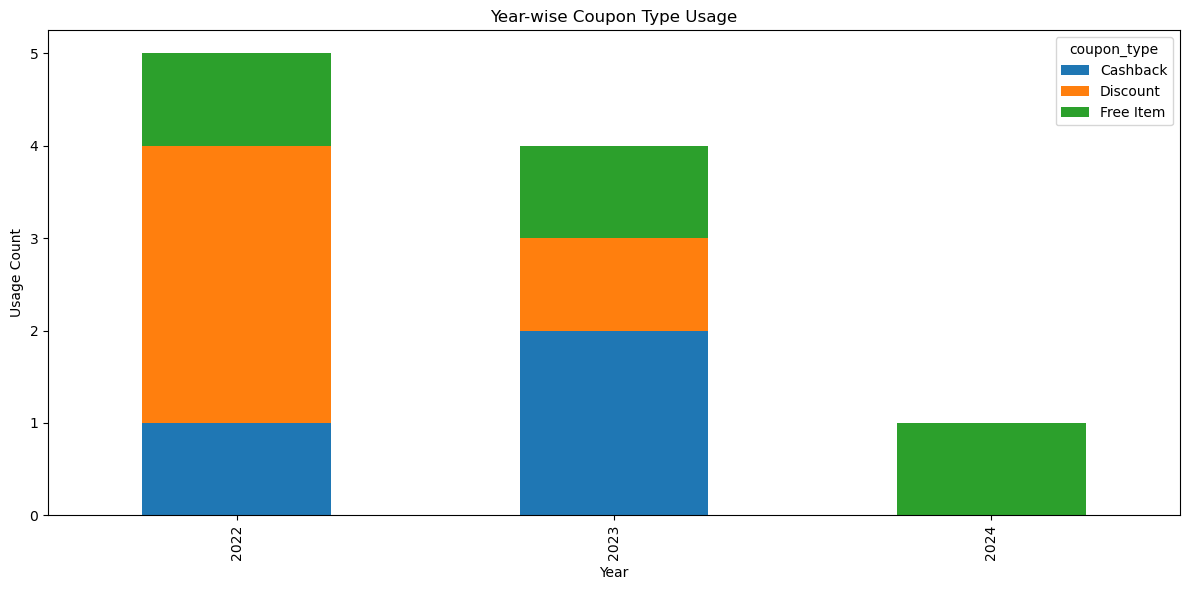

In [10]:
# Convert to datetime if not already
df['purchase_date'] = pd.to_datetime(df['purchase_date'])
df['year'] = df['purchase_date'].dt.year

yearly_coupon_usage = df.groupby(['year', 'coupon_type']).size().unstack().fillna(0)
yearly_coupon_usage.plot(kind='bar', stacked=True, figsize=(12,6), title='Year-wise Coupon Type Usage')
plt.ylabel('Usage Count')
plt.xlabel('Year')
plt.tight_layout()
plt.show()

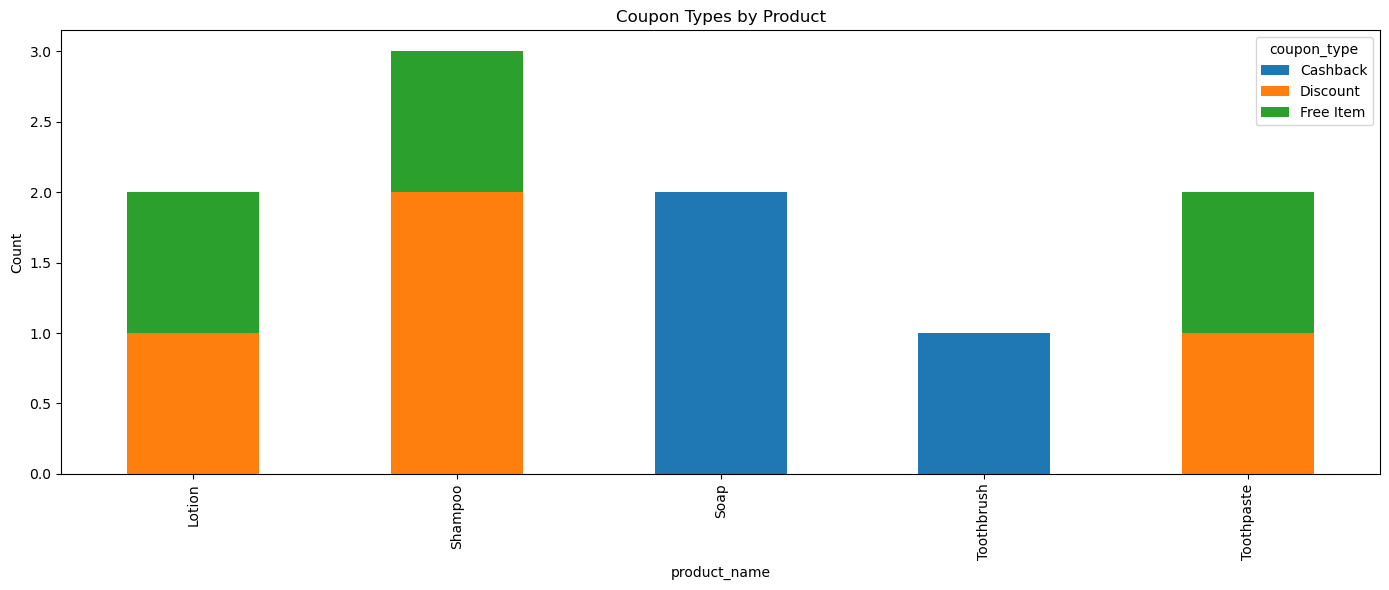


Feature Engineered Data Preview:
  product_name coupon_type  original_price  final_price  discount_amount  \
0      Shampoo    Discount             120          100               20   
1         Soap    Cashback              30           25                5   
2   Toothpaste    Discount              80           65               15   
3       Lotion   Free Item             250          250                0   
4      Shampoo    Discount             120           90               30   

   discount_percentage  
0            16.666667  
1            16.666667  
2            18.750000  
3             0.000000  
4            25.000000  


In [12]:
#  Coupon Classification by Product
coupon_by_product = df.groupby(['product_name', 'coupon_type']).size().unstack().fillna(0)
coupon_by_product.plot(kind='bar', stacked=True, figsize=(14,6), title='Coupon Types by Product')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

#  Feature Engineering 
if 'original_price' in df.columns and 'final_price' in df.columns:
    df['discount_amount'] = df['original_price'] - df['final_price']
    df['discount_percentage'] = (df['discount_amount'] / df['original_price']) * 100

# View engineered features
print("\nFeature Engineered Data Preview:")
print(df[['product_name', 'coupon_type', 'original_price', 'final_price', 'discount_amount', 'discount_percentage']].head())
